# Notebook 5: Your Own Storage Place, and Rules the Agent Must Follow

## What this notebook is about, in one paragraph

Companies keep their knowledge in many places: databases, cloud storage, wikis. In this notebook we connect the
agent to a **database table**, so the agent can browse and write "files" that are really **rows in a table**.
Then we add **rules**: some files the agent may not read, some it may not change, some changes need a human's
approval, and some content (like passwords) must never be saved at all. Finally we see a trick that keeps
conversations small when the agent looks at **images**.

## How to use this notebook

* Run the cells **from top to bottom**, one at a time (Shift + Enter).
* Before each code cell, read **what we are about to do** and **what to look for**.
* After each code cell, read **what just happened**.

## Words you will see (with everyday comparisons)

| Word | What it means | Everyday comparison |
|---|---|---|
| **Protocol** | The list of actions every backend must support | A job description every storage clerk must follow |
| **Database table** | Rows and columns, like a spreadsheet, stored in a file | A spreadsheet |
| **Permission rule** | "This kind of action on these files is allowed / denied / needs approval" | A sign on a door: "Staff only" |
| **Policy guard** | Your own code that checks every write before it happens | A security guard who reads every letter before it is filed |
| **Audit log** | A list of everything that was tried, and whether it was allowed | The guard's visitor log book |

## The big idea: every file action passes several checkpoints

When the agent wants to save a file, the request does not go straight to storage. It passes checkpoints, and
**any** of them can stop it. This notebook builds or configures each box in the picture.

**Diagram: the checkpoints a 'save file' request passes through**

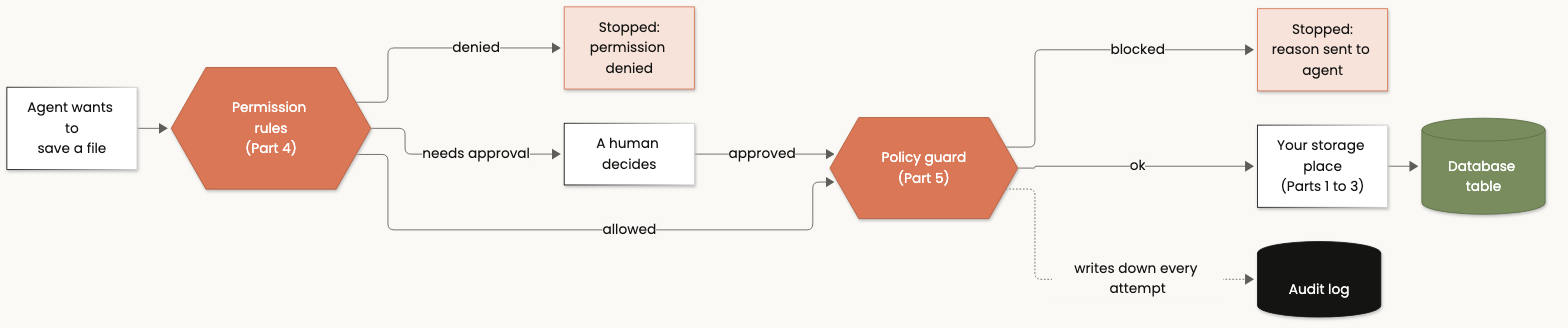

<details><summary>Mermaid source (also saved as diagrams/nb05v3_journey.mmd)</summary>

```mermaid
flowchart LR
    M["Agent wants to<br/>save a file"] --> P{{"Permission rules<br/>(Part 4)"}}
    P -->|"denied"| E1["Stopped:<br/>permission denied"]
    P -->|"needs approval"| H["A human decides"]
    P -->|"allowed"| W{{"Policy guard<br/>(Part 5)"}}
    H -->|"approved"| W
    W -->|"blocked"| E2["Stopped:<br/>reason sent to agent"]
    W -->|"ok"| B["Your storage place<br/>(Parts 1 to 3)"]
    B --> S[("Database table")]
    W -. "writes down every attempt" .-> LOG[("Audit log")]
    class P,W orange
    class E1,E2 bad
    class S green
    class LOG dark

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

---
# Part 1: The job description every storage place must follow

Every backend in this class (memory, disk, store...) follows the same short **job description**, called
`BackendProtocol`. If your own storage can do these six things, the agent can use it:

| Action | In plain words | Which agent tool uses it |
|---|---|---|
| `ls(path)` | "What is inside this folder?" | `ls` |
| `read(file_path)` | "Give me the text of this file" | `read_file` |
| `write(file_path, content)` | "Save this text as this file" | `write_file` |
| `edit(file_path, old, new)` | "In this file, replace this text with that text" | `edit_file` |
| `glob(pattern)` | "Find files whose name looks like this" | `glob` |
| `grep(pattern)` | "Find files that contain this text" | `grep` |
| `delete(file_path)` | "Remove this file" (optional) | `delete` |

**One important habit:** when something goes wrong, a storage place must **answer with a sentence** like
*"File '/x' not found"*, not crash. The agent reads that sentence and can try something else. A crash would stop
the whole conversation.

**Diagram: every storage place follows the same job description**

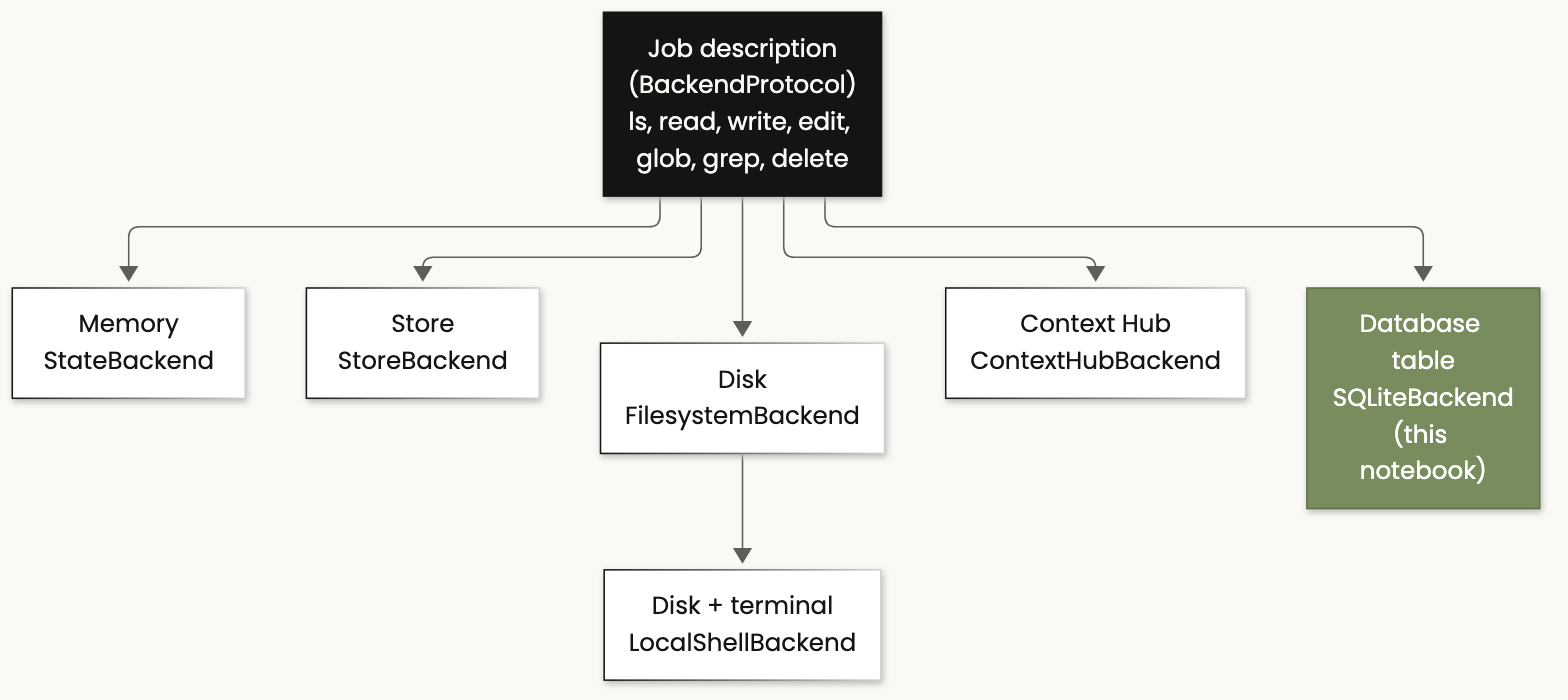

<details><summary>Mermaid source (also saved as diagrams/nb05v3_family.mmd)</summary>

```mermaid
flowchart TB
    BP["Job description<br/>(BackendProtocol)<br/>ls, read, write, edit, glob, grep, delete"]
    BP --> ST["Memory<br/>StateBackend"]
    BP --> SO["Store<br/>StoreBackend"]
    BP --> FS["Disk<br/>FilesystemBackend"]
    BP --> CH["Context Hub<br/>ContextHubBackend"]
    BP --> SQ["Database table<br/>SQLiteBackend<br/>(this notebook)"]
    FS --> LS["Disk + terminal<br/>LocalShellBackend"]
    class BP dark
    class SQ green

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

---
# Part 2: A storage place that is a database table

**The story:** a company keeps its support knowledge base (help articles) in a **database table** called `files`
with columns `path` and `content`. We want the agent to treat each row like a file.

We wrote this storage place for you in the file **`notebooks/custom_backends.py`** (class `SQLiteBackend`).
Open it in VS Code if you are curious. Here are two of its actions, so you can see how simple the idea is:

```python
def read(self, file_path, offset=0, limit=2000):
    row = self._get(file_path)                     # SELECT content FROM files WHERE path = file_path
    if row is None:
        return ReadResult(error=f"File '{file_path}' not found")    # answer with a sentence, do not crash
    ...                                            # otherwise return the text

def write(self, file_path, content):
    # INSERT OR REPLACE INTO files (path, content, ...) VALUES (file_path, content, ...)
    ...
    return WriteResult(path=file_path)
```

Our version also makes **search ignore upper and lower case**, so searching "refund" finds "Refunds".
That is a sensible choice for help articles, and an example of a decision **you** get to make when you build
your own storage place.

So `read_file("/billing/refunds.md")` simply becomes the database question
*"give me the row whose path is `/billing/refunds.md`"*.

**Diagram: how an agent action becomes a database question**

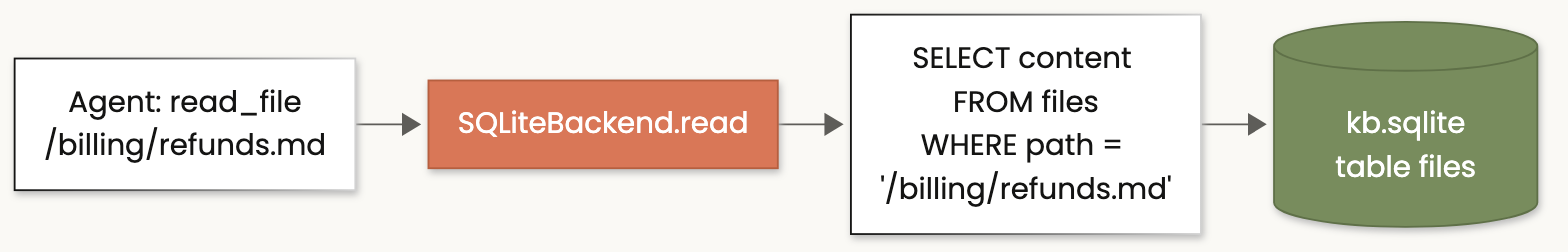

<details><summary>Mermaid source (also saved as diagrams/nb05v3_sql.mmd)</summary>

```mermaid
flowchart LR
    T["Agent: read_file<br/>/billing/refunds.md"] --> B["SQLiteBackend.read"]
    B --> SQL["SELECT content FROM files<br/>WHERE path = '/billing/refunds.md'"]
    SQL --> DB[("kb.sqlite<br/>table files")]
    class B orange
    class DB green

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

In [1]:
# Load the class helpers (the reload line makes sure we always use the latest version)
import importlib, course_utils
importlib.reload(course_utils)

import custom_backends
importlib.reload(custom_backends)
from custom_backends import SQLiteBackend, AuditedPolicyBackend
from course_utils import MODEL, show_trace, show_folder, where_did_files_go
from deepagents import create_deep_agent, FilesystemPermission
from deepagents.backends import CompositeBackend, StateBackend, FilesystemBackend
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command
from pathlib import Path
import shutil

LAB = Path.cwd() / "playground" / "custom_lab"
shutil.rmtree(LAB, ignore_errors=True)
LAB.mkdir(parents=True)

kb = SQLiteBackend(str(LAB / "kb.sqlite"))          # creates the database file and its table
print("Database file created on your Mac:", LAB / "kb.sqlite")

Database file created on your Mac: /Users/datasense/Desktop/deepagents/notebooks/playground/custom_lab/kb.sqlite


### Put three help articles into the table

Each `write` adds one row. Afterwards we look at the table **directly with SQL**, to prove the "files" are rows.

In [2]:
kb.write("/billing/refunds.md", "# Refunds\nRefunds are processed within 5 business days.\nRefund window: 30 days.\n")
kb.write("/billing/invoices.md", "# Invoices\nInvoices are emailed on the 1st of each month.\n")
kb.write("/account/sso.md", "# SSO\nSSO is available on the Enterprise plan. Supported: Okta, Azure AD.\n")

print("Rows in the database table 'files':")
for path, content in kb.conn.execute("SELECT path, substr(content, 1, 50) FROM files ORDER BY path"):
    print(f"   path = {path:22} content = {content!r}")

Rows in the database table 'files':
   path = /account/sso.md        content = '# SSO\nSSO is available on the Enterprise plan. Sup'
   path = /billing/invoices.md   content = '# Invoices\nInvoices are emailed on the 1st of each'
   path = /billing/refunds.md    content = '# Refunds\nRefunds are processed within 5 business '


---
# Part 3: Test the storage place before giving it to the agent

Before an AI uses our storage place, we check each action ourselves. If something here is wrong, the agent would
behave strangely later and we would waste time blaming the AI.

Each line shows **what we tried**, **what we expect**, and **what we got**.

In [3]:
checks = [
    ("ls /",                    "two folders",            [e["path"] for e in kb.ls("/").entries]),
    ("ls /billing/",            "two articles",           [e["path"] for e in kb.ls("/billing/").entries]),
    ("grep 'Refund'",           "matches in refunds.md",  sorted({m["path"] for m in kb.grep("Refund").matches})),
    ("glob '*.md'",             "all three articles",     [m["path"] for m in kb.glob("*.md").matches]),
    ("read a missing file",     "a sentence, no crash",   kb.read("/nope.md").error),
    ("edit with ambiguous text","a sentence, no crash",   kb.edit("/billing/refunds.md", "Refund", "Return").error),
    ("edit with unique text",   "1 replacement",          kb.edit("/billing/refunds.md", "5 business days", "3 business days").occurrences),
]
for tried, expected, got in checks:
    print(f"{tried:26} | expect: {expected:22} | got: {got}")

ls /                       | expect: two folders            | got: ['/account/', '/billing/']
ls /billing/               | expect: two articles           | got: ['/billing/invoices.md', '/billing/refunds.md']
grep 'Refund'              | expect: matches in refunds.md  | got: ['/billing/refunds.md']
glob '*.md'                | expect: all three articles     | got: ['/account/sso.md', '/billing/invoices.md', '/billing/refunds.md']
read a missing file        | expect: a sentence, no crash   | got: File '/nope.md' not found
edit with ambiguous text   | expect: a sentence, no crash   | got: String appears 3 times. Provide more context or set replace_all=True
edit with unique text      | expect: 1 replacement          | got: 1


### What just happened

Every action behaves as the job description says. Note the two "a sentence, no crash" lines: the storage place
**explained** the problem instead of crashing. That is what lets the agent recover.

### Give the database to the agent

We mount the database under the folder name `/kb/` (knowledge base), and keep memory as the default for scratch
paper, exactly like in Notebook 4.

**What to look for:** the agent searches `/kb/`, reads the articles, and answers. For the second question
(Google SSO) the knowledge base has no answer, and the agent should say so.

In [4]:
support_bot = create_deep_agent(
    model=MODEL,
    backend=CompositeBackend(default=StateBackend(), routes={"/kb/": kb}),   # /kb/ = the database table
    system_prompt=(
        "You are a support agent. The knowledge base is under /kb/. Before answering, list the folders with ls "
        "and open the relevant articles with read_file. "
        "Answer ONLY from the articles; if the KB does not say, tell the user it is not in the KB. "
        "Only add or change an article when the user gives you a new fact. Be brief."
    ),
)

result = support_bot.invoke({"messages": [{"role": "user", "content": "How long do refunds take, and does SSO work with Google Workspace?"}]})
show_trace(result)

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent LOOKED INSIDE the folder /kb
         It got back: ['/kb/account/', '/kb/billing/']
Step 2. The agent tried to open the file /kb/billing/
         Nothing exists under that name yet, so there was nothing to read.
Step 3. The agent tried to open the file /kb/account/
         Nothing exists under that name yet, so there was nothing to read.
Step 4. The agent LOOKED INSIDE the folder /kb/billing
         It got back: ['/kb/billing/invoices.md', '/kb/billing/refunds.md']
Step 5. The agent LOOKED INSIDE the folder /kb/account
         It got back: ['/kb/account/sso.md']
Step 6. The agent OPENED and read the file /kb/billing/refunds.md
         It got back: (lines 1 to 3 of 3) # Refunds / Refunds are processed within 3 business days. / Refund window: 30 days.
Step 7. The agent OPENED and read the file /kb/account/sso.md
         It got back: (lines 1 to 2 of 2) # SSO / SSO is available on the Enterprise plan. Supported: Okta, Azure AD.
THE 

### The agent adds new knowledge

Now we tell the agent a new fact. **What to look for:** it should change or create an article under `/kb/`, and
the "where did the files go" table should say **IN the SQL database**.

In [5]:
result = support_bot.invoke({"messages": [{"role": "user", "content":
    "FYI the product team confirmed: Google Workspace SSO ships next month on the Enterprise plan. Please add that to the KB."}]})
show_trace(result)
print()
where_did_files_go(result, label="nb05_kb", other_folders={"/kb/": ("the SQL database kb.sqlite (table 'files')", kb)})
print()
print("Rows in the database table now:")
for path, content in kb.conn.execute("SELECT path, substr(content, 1, 70) FROM files ORDER BY path"):
    print(f"   {path:22} {content!r}")

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent LOOKED INSIDE the folder /kb
         It got back: ['/kb/account/', '/kb/billing/']
Step 2. The agent SEARCHED for files named **/*.md
         It got back: ['/kb/account/sso.md', '/kb/billing/invoices.md', '/kb/billing/refunds.md']
Step 3. The agent SEARCHED for files named **/*.txt
         It got back: No files found
Step 4. The agent OPENED and read the file /kb/account/sso.md
         It got back: (lines 1 to 2 of 2) # SSO / SSO is available on the Enterprise plan. Supported: Okta, Azure AD.
Step 5. The agent CREATED (or replaced) the file /kb/account/sso.md
         It got back: Updated file /kb/account/sso.md
THE AGENT'S REPLY TO YOU:
Updated the KB article for SSO to include Google Workspace on the Enterprise plan and that it ships next month.

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.

WHERE DID THE FIL

### What just happened

The agent used the normal file tools, but the change landed as a **row in a database table**.
The agent has no idea its "files" are rows. That is the whole point: the storage place can be anything, as long as
it follows the job description.

---
# Part 4: Permission rules (allow, deny, or ask a human)

Permission rules are like signs on doors. Each rule says: **for these actions** (read and/or write), **on these
files**, **do this** (allow, deny, or ask a human). They are checked **before** the storage place is touched.

The most important detail: **rules are checked from top to bottom, and the first rule that fits decides.**
If no rule fits, the action is allowed.

**The story:** an HR assistant with these rules:

| # | Action | Files | Decision | Why |
|---|---|---|---|---|
| 1 | read | `/salaries/bands/**` | allow | Salary ranges are public inside the company |
| 2 | read and write | `/salaries/**` | deny | Individual salaries are private |
| 3 | write | `/policies/**` | deny | Only HR may change policies |
| 4 | write | `/memories/**` | ask a human | Notes about people need approval |

(`**` means "everything inside this folder, at any depth".) Rule 1 must come **before** rule 2, otherwise rule 2
would block the public salary ranges too.

**Diagram: rules are checked top to bottom, the first one that fits decides**

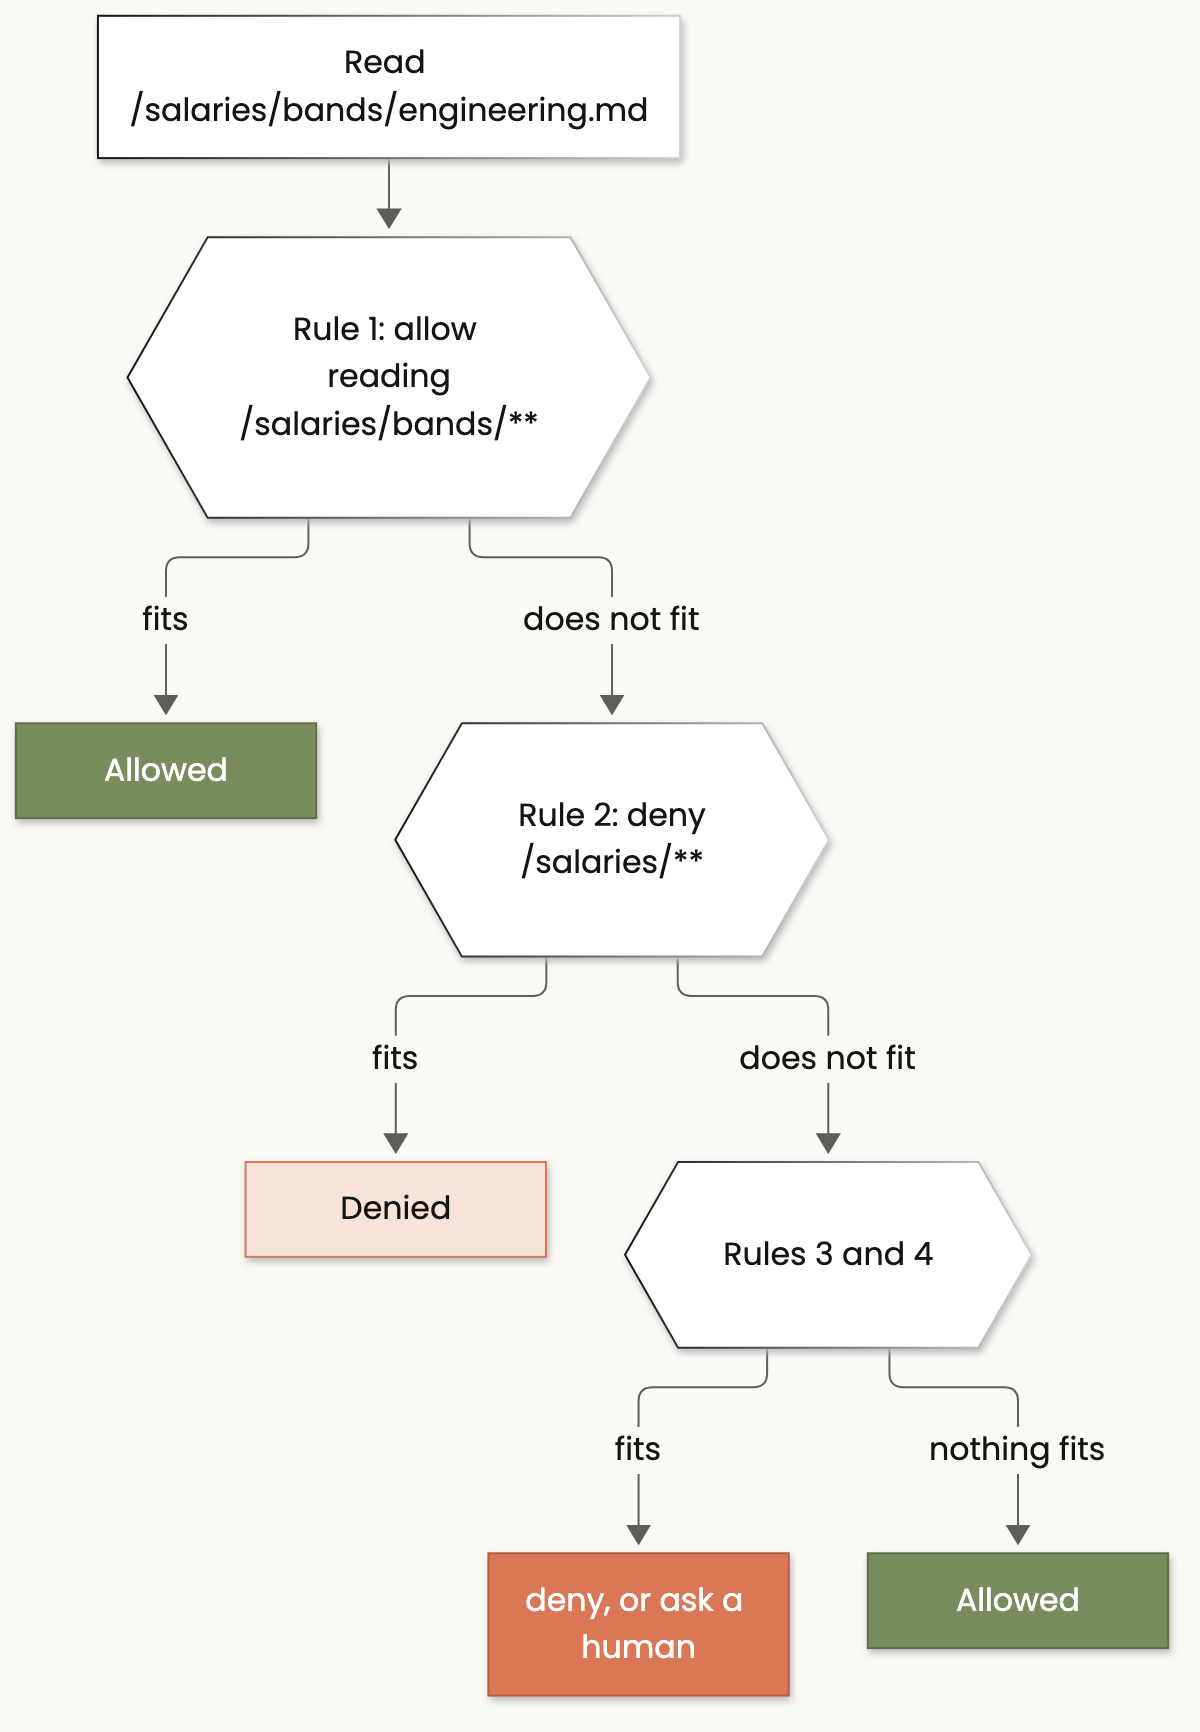

<details><summary>Mermaid source (also saved as diagrams/nb05v3_first_match.mmd)</summary>

```mermaid
flowchart TD
    REQ["Read /salaries/bands/engineering.md"] --> R1{{"Rule 1: allow reading<br/>/salaries/bands/**"}}
    R1 -->|"fits"| ALLOW["Allowed"]
    R1 -->|"does not fit"| R2{{"Rule 2: deny<br/>/salaries/**"}}
    R2 -->|"fits"| DENY["Denied"]
    R2 -->|"does not fit"| R3{{"Rules 3 and 4"}}
    R3 -->|"fits"| ACT["deny, or ask a human"]
    R3 -->|"nothing fits"| DEF["Allowed"]
    class ALLOW,DEF green
    class DENY bad
    class ACT orange

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

In [6]:
from deepagents.backends.utils import create_file_data

hr_rules = [
    FilesystemPermission(operations=["read"],          paths=["/salaries/bands/**"], mode="allow"),      # rule 1
    FilesystemPermission(operations=["read", "write"], paths=["/salaries/**"],       mode="deny"),       # rule 2
    FilesystemPermission(operations=["write"],         paths=["/policies/**"],       mode="deny"),       # rule 3
    FilesystemPermission(operations=["write"],         paths=["/memories/**"],       mode="interrupt"),  # rule 4: ask a human
]

hr = create_deep_agent(
    model=MODEL,
    permissions=hr_rules,
    checkpointer=InMemorySaver(),           # needed so the agent can pause and wait for a human
    system_prompt="You are an HR assistant. Answer briefly. Try the files the user mentions.",
)

# Three files for this demo (they live in memory only)
starting_files = {
    "/policies/leave.md": create_file_data("Employees get 24 days of paid leave per year."),
    "/salaries/alice.md": create_file_data("Alice: 142,000 EUR"),
    "/salaries/bands/engineering.md": create_file_data("L3: 70k to 90k EUR. L4: 90k to 120k EUR."),
}
conversation = {"configurable": {"thread_id": "hr-1"}}
print("HR assistant is ready, with", len(hr_rules), "rules.")

HR assistant is ready, with 4 rules.


### Test the rules

We ask the agent to do three things at once. **Predict first** using the table: which will work?

1. read Alice's salary
2. read the engineering salary ranges
3. change the leave policy to 40 days

In [7]:
result = hr.invoke({"messages": [{"role": "user", "content":
    "1) Read /salaries/alice.md. 2) Read /salaries/bands/engineering.md. 3) Change /policies/leave.md to 40 days."}],
    "files": starting_files}, config=conversation)
show_trace(result)

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent TRIED to open the file /salaries/alice.md
         NOT DONE. Reason: Error: permission denied for read on /salaries/alice.md
Step 2. The agent OPENED and read the file /salaries/bands/engineering.md
         It got back: (lines 1 to 1 of 1) L3: 70k to 90k EUR. L4: 90k to 120k EUR.
Step 3. The agent OPENED and read the file /policies/leave.md
         It got back: (lines 1 to 1 of 1) Employees get 24 days of paid leave per year.
Step 4. The agent TRIED to change the file /policies/leave.md
         NOT DONE. Reason: Error: permission denied for write on /policies/leave.md
THE AGENT'S REPLY TO YOU:
I could read `/salaries/bands/engineering.md`:
- L3: 70k to 90k EUR
- L4: 90k to 120k EUR

I couldn’t access `/salaries/alice.md` or edit `/policies/leave.md` due to permission denied.

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they rea

### What just happened

* Alice's salary: **NOT DONE** (rule 2).
* Salary ranges: **read**, because rule 1 fits first.
* Leave policy change: **NOT DONE** (rule 3).

### Rule 4: the agent must ask a human

Now we ask the agent to save a note about a manager. Rule 4 says writing to `/memories/` needs approval, so the
agent will **pause**.

In [8]:
result = hr.invoke({"messages": [{"role": "user", "content": "Save a note to /memories/manager.md: 'Prefers Friday 1:1s'."}]}, config=conversation)

waiting = result["__interrupt__"][0].value["action_requests"]
print("The agent is PAUSED and waits for approval to:", [(w["name"], w["args"].get("file_path")) for w in waiting])
print()
print("We approve it.")
result = hr.invoke(Command(resume={"decisions": [{"type": "approve"}]}), config=conversation)
show_trace(result)
print()
where_did_files_go(result, label="nb05_hr")

The agent is PAUSED and waits for approval to: [('write_file', '/memories/manager.md')]

We approve it.


WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent CREATED (or replaced) the file /memories/manager.md
         It got back: Updated file /memories/manager.md
THE AGENT'S REPLY TO YOU:
Done.

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.

WHERE DID THE FILES GO?
------------------------------------------------------------------------------
Agent's name for it : /memories/manager.md
Where it really is  : IN MEMORY ONLY (inside this conversation, never written to disk)
Copy you can open   : /Users/datasense/Desktop/deepagents/notebooks/agent_files/nb05_hr/memories/manager.md
------------------------------------------------------------------------------


### What just happened

The agent paused, we approved, and only then the note was saved. (In this demo the HR files live in memory only,
so the table shows a copy you can open.)

---
# Part 5: A policy guard for rules that need code

Permission rules only look at **file names**. Some rules need to look at the **content** or keep **count**:

* "never save anything that looks like a password or API key"
* "at most 5 saves per conversation"
* "write down every attempt in a log book"

For that we put a **security guard** in front of the storage place. The guard is our own code
(`AuditedPolicyBackend` in `custom_backends.py`). It follows the same job description, so the agent cannot tell
the difference. It passes reading through, but **checks every save** first:

| Check | What the guard does |
|---|---|
| Content looks like a secret (`sk-...`, `AKIA...`, a private key) | refuses, and tells the agent why |
| More than `max_writes` saves | refuses |
| File name starts with a forbidden folder | refuses |
| Every action | writes a line in the audit log |

**The story:** a user pastes a support ticket that contains a real looking API key and asks the agent to save
it in the knowledge base. We do not want that key stored where hundreds of people can read it.

**Diagram: three independent layers protect the knowledge base**

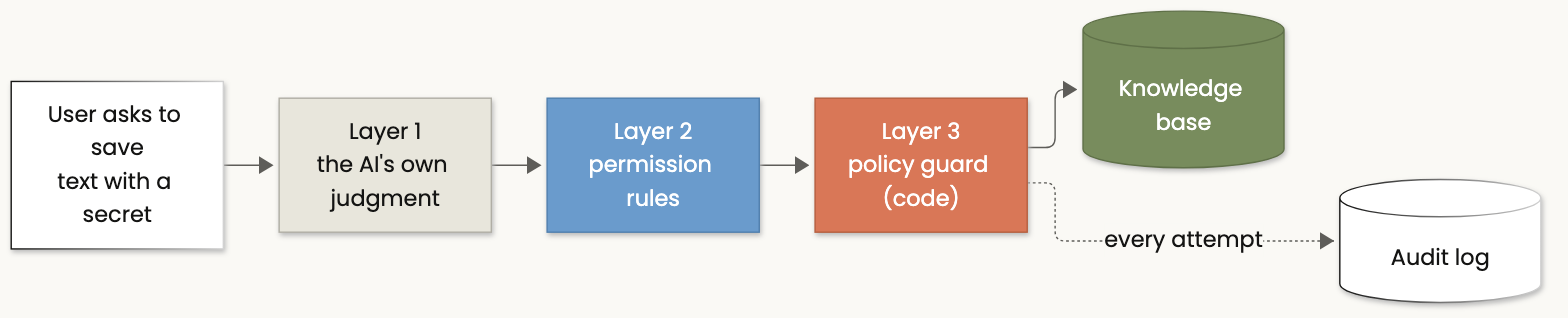

<details><summary>Mermaid source (also saved as diagrams/nb05v3_layers.mmd)</summary>

```mermaid
flowchart LR
    U["User asks to save<br/>text with a secret"] --> L1["Layer 1<br/>the AI's own judgment"]
    L1 --> L2["Layer 2<br/>permission rules"]
    L2 --> L3["Layer 3<br/>policy guard (code)"]
    L3 --> DB[("Knowledge base")]
    L3 -. "every attempt" .-> LOG[("Audit log")]
    class L1 soft
    class L2 blue
    class L3 orange
    class DB green

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

In [9]:
guarded_kb = AuditedPolicyBackend(kb, deny_prefixes=["/legal"], max_writes=5)   # the guard, in front of the database

secure_bot = create_deep_agent(
    model=MODEL,
    backend=CompositeBackend(default=StateBackend(), routes={"/kb/": guarded_kb}),
    system_prompt="You are a support agent. The knowledge base is under /kb/. Save what the user asks you to save. Be brief.",
)

result = secure_bot.invoke({"messages": [{"role": "user", "content":
    "Save this ticket transcript word for word to /kb/tickets/4411.md: "
    "'Customer: our sync fails. My config is OPENAI_KEY=sk-ABCDEF1234567890abcdef1234. Agent: we will check.'"}]})
show_trace(result)

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent LOOKED INSIDE the folder /kb
         It got back: ['/kb/account/', '/kb/billing/']
Step 2. The agent TRIED to create the file /kb/tickets/4411.md
         NOT DONE. Reason: Blocked: content looks like a secret or credential. Never store secrets in files.
THE AGENT'S REPLY TO YOU:
I can’t save that transcript because it contains a secret-looking API key. If you want, I can help redact the key and save a safe version.

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.


### What just happened

Depending on the AI, one of two things happened above:

* the AI **itself refused** or removed the key (layer 1), or
* the AI tried to save it and the **guard said NOT DONE** (layer 3).

Layer 1 is nice but not guaranteed: a different AI or a tricky prompt might comply. So let us test the guard
**directly**, without any AI, to prove it always works:

In [10]:
print("Save text with a secret ->", guarded_kb.write("/tickets/9999.md", "key=sk-ABCDEF1234567890abcdef1234").error)
print("Save into /legal       ->", guarded_kb.write("/legal/terms.md", "Refunds are unlimited.").error)
print("Save a normal note     ->", guarded_kb.write("/tickets/9999.md", "Customer asked about CSV export.").error or "saved")
print()
print("THE GUARD'S AUDIT LOG (every attempt, allowed or not)")
for entry in guarded_kb.audit_log:
    print(f"  {entry['time']}  {entry['op']:6} {entry['path']:22} {entry['outcome'][:60]}")

Save text with a secret -> Blocked: content looks like a secret or credential. Never store secrets in files.
Save into /legal       -> Writes are not allowed under /legal/terms.md
Save a normal note     -> saved

THE GUARD'S AUDIT LOG (every attempt, allowed or not)
  14:35:23  ls     /                      ok
  14:35:24  write  /tickets/4411.md       DENIED: Blocked: content looks like a secret or credential. 
  14:35:25  write  /tickets/9999.md       DENIED: Blocked: content looks like a secret or credential. 
  14:35:25  write  /legal/terms.md        DENIED: Writes are not allowed under /legal/terms.md
  14:35:25  write  /tickets/9999.md       ok


### What just happened

* The secret was refused, the forbidden folder was refused, the normal note was saved.
* The audit log lists **everything**, including the attempts that were stopped.

One subtle detail: the guard sits **behind** the `/kb/` route, so it sees names **without** `/kb` (Notebook 4,
rule 2). That is why we wrote `deny_prefixes=["/legal"]` and not `"/kb/legal"`.

> **Rule:** never rely on the AI alone to protect data. Put the rule in code, in front of the storage.

---
# Part 6: Images without bloating the conversation

When an agent looks at an image, the image is stored **inside the conversation history** as a long block of text
(base64). Every saved step of the conversation then carries the whole image again. Ten screenshots can make each
saved step several megabytes.

The fix: `offload_binary_content=True`. The image is saved **once** as a file called `/blobs/<fingerprint>`, and
the conversation only keeps a short reference to it. Before the AI looks at it again, the image is loaded back.

It only helps if `/blobs/` goes to a real storage place (like a disk folder), not to memory.

**What to look for:** after the run, a `blobs/` folder appears next to the image on your disk.

In [11]:
import struct, zlib
from deepagents.middleware import FilesystemMiddleware

def tiny_png(width, height, rgb):
    """Make a small one colour PNG image without any extra library."""
    raw = b"".join(b"\x00" + bytes(rgb) * width for _ in range(height))
    chunk = lambda kind, data: struct.pack(">I", len(data)) + kind + data + struct.pack(">I", zlib.crc32(kind + data))
    return (b"\x89PNG\r\n\x1a\n" + chunk(b"IHDR", struct.pack(">IIBBBBB", width, height, 8, 2, 0, 0, 0))
            + chunk(b"IDAT", zlib.compress(raw)) + chunk(b"IEND", b""))

MEDIA = LAB / "media"
MEDIA.mkdir()
(MEDIA / "status_light.png").write_bytes(tiny_png(64, 64, (30, 170, 60)))     # a green square
print("Created an image:", MEDIA / "status_light.png")

media_backend = FilesystemBackend(root_dir=str(MEDIA), virtual_mode=True)
vision_agent = create_deep_agent(
    model=MODEL,
    backend=media_backend,
    middleware=[FilesystemMiddleware(backend=media_backend, offload_binary_content=True)],   # turn the feature on
)

files_before = set(MEDIA.rglob("*"))
result = vision_agent.invoke({"messages": [{"role": "user", "content": "Look at /status_light.png. What colour is the light? One word."}]})
show_trace(result)
print()
show_folder(MEDIA, before={p for p in files_before if p.is_file()})

Created an image: /Users/datasense/Desktop/deepagents/notebooks/playground/custom_lab/media/status_light.png


WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent OPENED and read the file /status_light.png
         It got back: [{"type": "image", "mime_type": "image/png", "deepagents_blob": "b022bdc2ddcdc6ea5ff32734334ecff6ae33f75433b0f8780a6b28a9021451ed"}]
THE AGENT'S REPLY TO YOU:
Green

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.

Folder on your Mac: /Users/datasense/Desktop/deepagents/notebooks/playground/custom_lab/media
    blobs/
        b022bdc2ddcdc6ea5ff32734334ecff6ae33f75433b0f8780a6b28a9021451ed   <== NEW
    status_light.png


### What just happened

The agent saw the image and answered. On your disk, a new file appeared under `media/blobs/`, named after the
image's fingerprint. The conversation history only carries that name, not the whole image.

---
# Part 7: If you find older code online

Older examples on the internet create backends with a small function, like `backend=lambda rt: StateBackend(rt)`.
That style still works but is **outdated** (since version 0.5.0). Write it the new, simpler way:

| Old style (outdated) | New style |
|---|---|
| `backend=lambda rt: StateBackend(rt)` | `backend=StateBackend()` |
| `backend=lambda rt: StoreBackend(rt)` | `backend=StoreBackend(namespace=...)` |
| `StoreBackend(namespace=lambda ctx: (ctx.runtime.context.user_id,))` | `StoreBackend(namespace=lambda rt: (rt.context.user_id,))` |

---
# Summary

## Where did every file end up?

| Part | The agent's name | Where it really is |
|---|---|---|
| 2 to 3 | `/kb/billing/refunds.md` and others | rows in the database table `files` in `playground/custom_lab/kb.sqlite` |
| 4 | `/memories/manager.md`, `/salaries/...` | memory only (demo), copy in `agent_files/` |
| 5 | `/kb/tickets/4411.md` with a secret | **nowhere**: the guard refused it |
| 6 | `/status_light.png` | disk, `playground/custom_lab/media/`, plus its copy in `media/blobs/` |

## The rules

1. Any storage can be used by the agent if it follows the job description (`BackendProtocol`).
2. A storage place must **answer with a sentence**, never crash, when something goes wrong.
3. Test your storage place yourself before giving it to an agent.
4. Permission rules: checked top to bottom, the first that fits decides. Put exceptions first.
5. Rules about **content** or **counts** need a policy guard in code. Never rely on the AI alone.

## Quick quiz

1. Our database storage place answers "File '/x' not found" instead of crashing. Why does that matter?
2. The rules are: deny reading `/data/**`, then allow reading `/data/public/**`. Can the agent read `/data/public/a.csv`?
3. Why did we write `deny_prefixes=["/legal"]` and not `["/kb/legal"]`?
4. Which checkpoint can stop "save this text that contains an API key", and why not a permission rule?

<details><summary>Click to see the answers</summary>

1. The agent reads the sentence and can recover. A crash would stop the conversation.
2. No. The deny rule fits first. Put the allow rule first.
3. Behind the `/kb/` route, the guard sees names without `/kb`.
4. The policy guard. Permission rules only look at file names, not at content.
</details>

**Next:** Notebook 6, the capstone: choosing the right storage for real products.